In [157]:
import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt
%matplotlib inline 

### read the dataset by the help of pandas

In [158]:
df_index=pd.read_csv('economic_index.csv')

In [159]:
df_index.head()

,Unnamed: 0,year,month,interest_rate,unemployment_rate,index_price
0,0,2017,12,2.75,5.3,1464
1,1,2017,11,2.50,5.3,1394
2,2,2017,10,2.50,5.3,1357
3,3,2017,9,2.50,5.3,1293
4,4,2017,8,2.50,5.4,1256


In [160]:
# drop the unnecessay column 
df_index.drop(columns=["Unnamed: 0","year","month"],inplace=True)
df_index.head()

,interest_rate,unemployment_rate,index_price
0,2.75,5.3,1464
1,2.50,5.3,1394
2,2.50,5.3,1357
3,2.50,5.3,1293
4,2.50,5.4,1256


In [161]:
# check null values 
df_index.isnull().sum()

interest_rate        0
unemployment_rate    0
index_price          0
dtype: int64

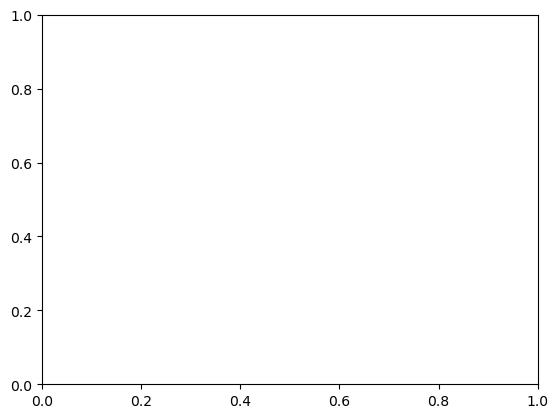

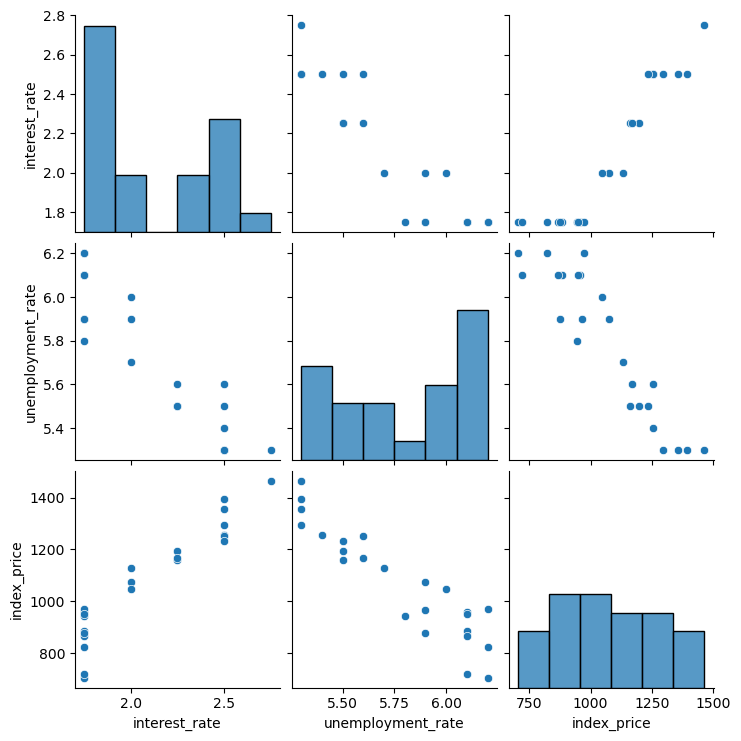

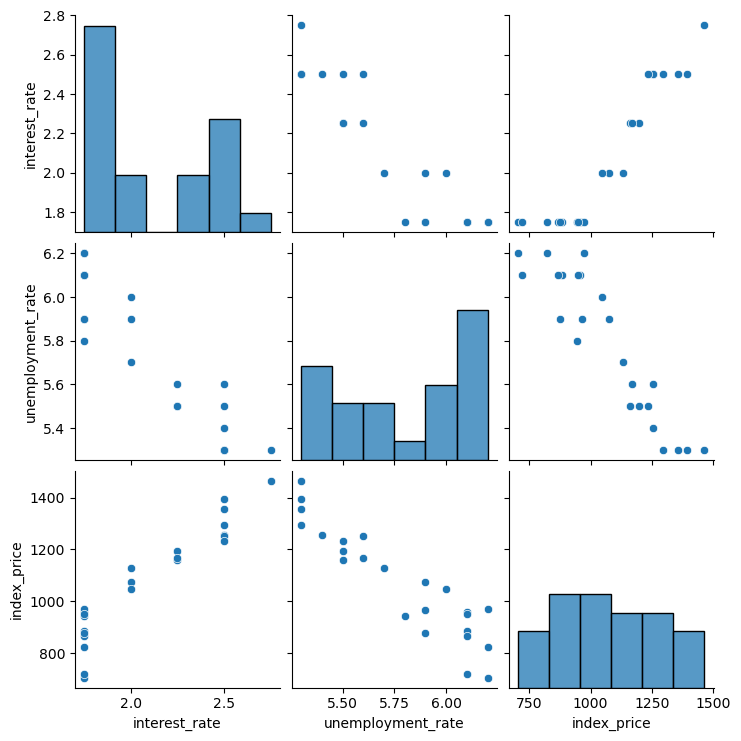

In [162]:
# let do some visualtion 
sns.pairplot(df_index)
plt.show(sns.pairplot(df_index)
)

In [165]:
df_index.corr()

,interest_rate,unemployment_rate,index_price
interest_rate,1.000000,-0.925814,0.935793
unemployment_rate,-0.925814,1.000000,-0.922338
index_price,0.935793,-0.922338,1.000000


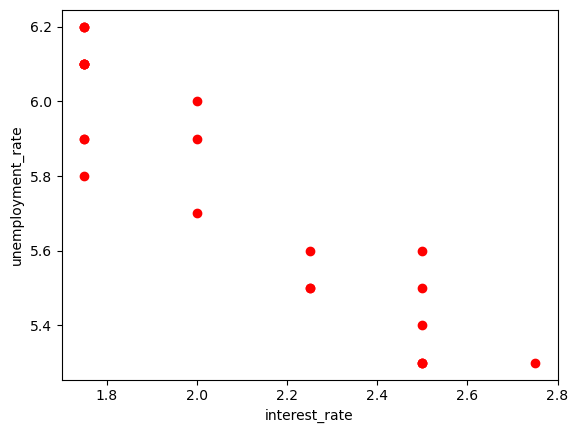

In [166]:
# visualtion at datapoint closely 
plt.scatter(df_index['interest_rate'],df_index['unemployment_rate'],color='r')
plt.xlabel('interest_rate')
plt.ylabel('unemployment_rate')
plt.show()

### Select input and output  feacture 


In [170]:
##independent and dependent features
X=df_index.iloc[:,:-1]
y=df_index.iloc[:,-1]

In [215]:
print("X shape:", X.shape)
print("y shape:", y.shape)

print("X type:", type(X))
print("y type:", type(y))

X shape: (24, 2)
y shape: (24,)
X type: <class 'pandas.core.frame.DataFrame'>
y type: <class 'pandas.core.series.Series'>


In [171]:
X.head(1)

,interest_rate,unemployment_rate
0,2.75,5.3


In [172]:
y.head(2)

0    1464
1    1394
Name: index_price, dtype: int64

### Train Test split 

In [218]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

### Train the model 


### Standarzation

In [219]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.fit_transform(X_test)

In [220]:
X_train
X_test

array([[ 0.40089186, -0.8660254 ],
       [-0.93541435,  1.15470054],
       [ 1.73719807, -1.44337567],
       [-0.93541435,  0.8660254 ],
       [-0.26726124,  0.28867513]])

### create multipl linear regression model 

In [221]:
from sklearn.linear_model import LinearRegression
regression=LinearRegression()
regression

LinearRegression()

In [222]:
# train the linear regression model 
regression.fit(X_train,y_train)

LinearRegression()

In [223]:
df_index.head(1)

,interest_rate,unemployment_rate,index_price
0,2.75,5.3,1464


In [224]:
regression.coef_

array([  86.63351334, -114.04857249])

In [225]:
regression.intercept_

np.float64(1059.4210526315792)

#### Make  the predication 

In [226]:
y_pred=regression.predict(X_test)

In [227]:
print(y_pred)
y_pred.shape

[1192.92068422  846.6908733  1374.53556008  879.61386031 1003.34428525]


(5,)

In [228]:
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)
print("y_predict:", y_predict.shape)

X_test: (5, 2)
y_test: (5,)
y_predict: (6,)


In [229]:
## cross validation
from sklearn.model_selection import cross_val_score
validation_score=cross_val_score(regression,X_train,y_train,scoring='neg_mean_squared_error',
                                cv=3)

In [230]:
np.mean(validation_score)

np.float64(-5674.031667186767)

### Evaluate Model Performance

In [232]:
from sklearn.metrics import r2_score

score = r2_score(y_test, y_pred)

print("R2 Score:", score)

R2 Score: 0.8507000324705947


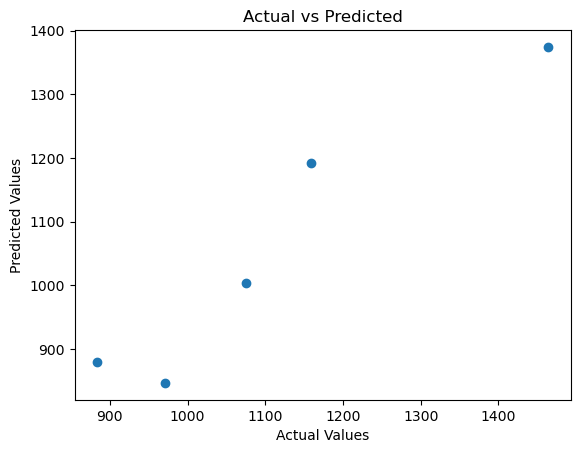

In [233]:
import matplotlib.pyplot as plt

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")

plt.title("Actual vs Predicted")

plt.show()

In [234]:
residuals=y_test-y_pred
print(residuals)

8     -33.920684
16    124.309127
0      89.464440
18      4.386140
11     71.655715
Name: index_price, dtype: float64


In [235]:
## Plot this residuals
sns.displot(residuals,kind='kde')

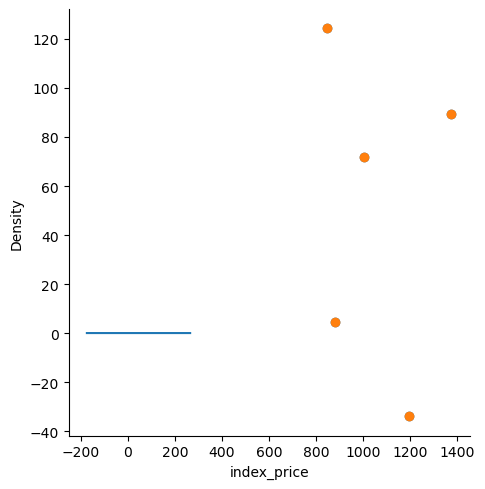

In [237]:
## scatter plot with respect to prediction and residuals
plt.scatter(y_pred,residuals)
plt.show()

### OLS Linear Regression
import statsmodels.api as sm
model=sm.OLS(y_train,X_train).fit()

In [238]:
## OLS Linear Regression
import statsmodels.api as sm
model=sm.OLS(y_train,X_train).fit()

In [239]:
model.summary()

C:\Users\Acer\anaconda3\Lib\site-packages\scipy\stats\_axis_nan_policy.py:430: UserWarning: `kurtosistest` p-value may be inaccurate with fewer than 20 observations; only n=19 observations were given.
  return hypotest_fun_in(*args, **kwds)


<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:            index_price   R-squared (uncentered):                   0.033
Model:                            OLS   Adj. R-squared (uncentered):             -0.081
Method:                 Least Squares   F-statistic:                             0.2916
Date:                Thu, 19 Nov 2026   Prob (F-statistic):                       0.751
Time:                        22:19:01   Log-Likelihood:                         -159.34
No. Observations:                  19   AIC:                                      322.7
Df Residuals:                      17   BIC:                                      324.6
Df Model:                           2                                                  
Covariance Type:            nonrobust                                                  
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
x1            86.6335    647.232      0.134      0.895   -1278.906    1452.173
x2          -114.0486    647.232     -0.176      0.862   -1479.588    1251.491
==============================================================================
Omnibus:                        0.676   Durbin-Watson:                   0.007
Prob(Omnibus):                  0.713   Jarque-Bera (JB):                0.526
Skew:                          -0.369   Prob(JB):                        0.769
Kurtosis:                       2.656   Cond. No.                         4.82
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

### Actual vs Predicted value 


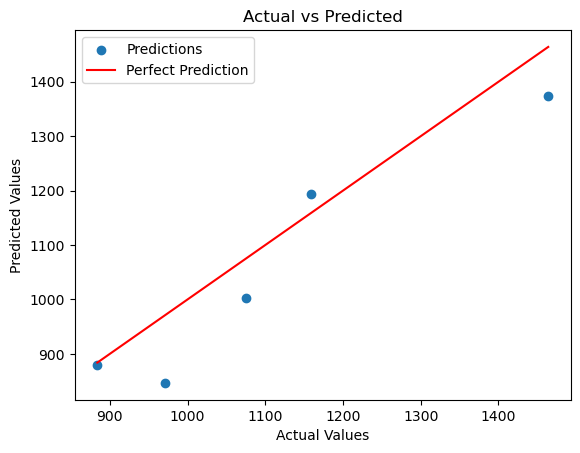

In [247]:
plt.scatter(y_test, y_pred, label="Predictions")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    label="Perfect Prediction"
)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")

plt.title("Actual vs Predicted")
plt.legend()

plt.show()

In [256]:
print(f"Actual Value {y_test} Predicted Value {y_pred} points.")


Actual Value 8     1159
16     971
0     1464
18     884
11    1075
Name: index_price, dtype: int64 Predicted Value [1192.92068422  846.6908733  1374.53556008  879.61386031 1003.34428525] points.


### Predictin for New value 

In [265]:
new_data=pd.DataFrame({
    'interest_rate':[1.75],
    'unemployment_rate':[5.8]
})

### . Predict New Index Price

In [266]:
prediction = model.predict(new_data)

print("Predicted Index Price:", prediction[0])

Predicted Index Price: -509.8730720737004


In [267]:
y_predict

array([1180.7466813 ,  802.74279699, 1379.83457045,  838.52599602,
        973.85313963, 1144.96348227])